In [2]:
#import corner
import numpy as np
import random
import pandas as pd
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib import dates
from sklearn.metrics import mean_squared_error, r2_score
from datetime import datetime
from lmfit import Minimizer, Parameters, Parameter, report_fit, printfuncs, conf_interval,minimize
from statsmodels.tsa.arima_model import ARIMA


from scipy.optimize import minimize
import scipy.stats as stats

#import numdifftools as ndt
import statsmodels.api as sm

%matplotlib inline



ModuleNotFoundError: No module named 'numdifftools'

In [4]:
def fetchData(fName,col=0,dType=int):
    myList = []
    file = open(fName,"r")
    for line in file:
        myList.append(dType(line.split()[col]))
        file.close()
    return myList

def getPmf(myList):
    pMap = {}
    nInv = 1./len(myList)
    for element in myList:
        if element not in pMap:
            pMap[element] = 0.
            pMap[element] += nInv
    return pMap

def bootstrap(myData,estimFunc,M=128):
    N = len(myData)
    h = [0.0]*M
    bootSamp = [0.0]*N
    for sample in range(M):
        for val in range(N):
            bootSamp[val] = myData[randint(0,N-1)]
            h[sample] = estimFunc(bootSamp)
            origEstim = estimFunc(myData)
            resError = basicStatistics(h)[1]
    return origEstim,resError

def myMleEstimate(myFunc,par,data):
    def lnL_av(x,par):
        N = len(x)
48
4 Increase your efficiency using Scientific Python (scipy)
11 lnL = 0.
12 for i in range(N):
13 lnL += scipy.log(myFunc(par,x[i]))
14 return lnL/N
15
16 objFunc = lambda s: -lnL_av(data,s)
17 par_mle = sciOpt.fmin(objFunc,par,disp=0)
18 return par_mle
19
20 fileName = sys.argv[1]
21 nBoot = int(sys.argv[2])
22
23 rawData = fetchData(fileName,1,float)
24
25 Rayleigh = lambda s,x: sciStat.rayleigh.pdf(x,scale=s)
26 objFunc = lambda x: myMleEstimate(Rayleigh,7.1,x)
27
28 s_av,s_Err = bootstrap(rawData,objFunc,nBoot)
29 print "# sigma = %lf +/- %lf (MLE)"%(s_av,s_Err)


SyntaxError: invalid syntax (<ipython-input-4-c40fe813b561>, line 34)

# step 0: data importation #

In [18]:
csv_url="https://raw.githubusercontent.com/ADelau/proj0016-epidemic-data/main/data.csv"
data = pd.read_csv(csv_url)
data['day_hospitalization']=data['num_cumulative_hospitalizations'].diff().shift(periods=-1)

In [29]:
data.head()

,Day,num_positive,num_tested,num_hospitalised,num_cumulative_hospitalizations,num_critical,num_fatalities,day_hospitalization
0,1,0,0,1,1,0,0,0.0
1,2,5,8,1,1,0,0,1.0
2,3,10,12,2,2,0,0,0.0
3,4,11,16,2,2,0,0,0.0
4,5,9,12,2,2,0,0,0.0


In [34]:
from numpy import genfromtxt
my_data = genfromtxt(csv_url, delimiter=',')
data4col=np.zeros((72,4))
for i in range(1,72):
    data4col[i-1][0]=my_data[i][0]
    data4col[i-1][1]=my_data[i][3]
    data4col[i-1][2]=my_data[i][5]
    data4col[i-1][3]=my_data[i][6]


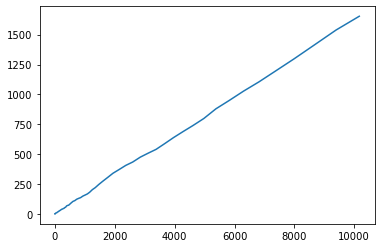

In [6]:
plt.plot(data['num_hospitalised'].cumsum(),data['num_cumulative_hospitalizations'])

# step 1: setting up the model #

In [68]:
np.round(4.5)

4.0

In [75]:
def transitionsS(y,p):
    result=np.zeros(10)
    
    # array ['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R','O_TREI_positive']
    result[0] =  np.round(y[1]*p[0]*y[0]/(1e6-y[6]))
    result[1] =  np.round(y[1]*p[1])
    result[2] = np.round(y[1]*p[1]*p[2])
    result[3] = np.round(y[3]*p[3])
    result[4] = np.round(y[4]*p[4])
    result[5] = np.round(y[5]*p[5])
    result[6] =  np.round(y[2]*p[6])
    result[7] =  np.round(y[3]*p[6])
    result[8] =  np.round(y[4]*p[7])
    result[9] =  np.round(y[5]*p[8])
    
    return result

In [76]:
def derivS(y, p):
    TR=transitionsS(y,p)
   # array ['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R','O_TREI_positive']
    dS = -TR[0]
    dE = TR[0] - TR[1] - TR[2]
    dC = TR[2] - TR[6]
    dI = TR[1] - TR[7] - TR[6]
    dH = TR[3] - TR[4] - TR[8]
    dICU = TR[4] - TR[5] - TR[9]
    dD = TR[5]
    
    return np.array([dS, dE, dC, dI, dH, dICU, dD]), TR

In [77]:
def fullsim(p,nbdays):

  
    dpop = np.zeros((nbdays,7))
    pop = np.zeros((nbdays,7))
    historique_transition = np.zeros((nbdays,10))
    
    
    pop[0]=np.array([p[-7],p[-6],p[-5],p[-4],p[-3],p[-2],p[-1]])
    dpop[0],historique_transition[0]=derivS(pop[0],p)

    for i in range(1,nbdays):
        pop[i]=pop[i-1]+dpop[i-1]
        dpop[i],historique_transition[i]=derivS(pop[i], p)
    
    return pop, dpop, historique_transition

In [78]:
result = np.zeros((10,4))
for i in range (0,10):
    result[i][0]=i
result

array([[0., 0., 0., 0.],
       [1., 0., 0., 0.],
       [2., 0., 0., 0.],
       [3., 0., 0., 0.],
       [4., 0., 0., 0.],
       [5., 0., 0., 0.],
       [6., 0., 0., 0.],
       [7., 0., 0., 0.],
       [8., 0., 0., 0.],
       [9., 0., 0., 0.]])

In [79]:
np.random.binomial(9, 0.5)

6

In [83]:
#p=['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R','Sensitiviy','S0','E0','I0','C0','H0','ICU0','D0']
def model(p,nbdays):
    result = np.zeros((nbdays,4))
    pop, dpop, historique_transition=fullsim(p,nbdays)
    for i in range (0,nbdays):
        result[i][0]=np.random.binomial(historique_transition[i][1],p[10])
        result[i][1]=pop[i][4]
        result[i][2]=pop[i][5]
        result[i][3]=pop[i][6]
    return result
    
    

In [5]:
def poisson_loglike(rate, data):
    ## make rate parameter into array of same length as data:
    r = np.ones(len(data))*rate
    ## now we can compute the log-likelihood:
    llike = -np.sum(r) + np.sum(data*np.log(r))-np.sum(scipy.special.gammaln(data + 1))
    return llike

In [66]:
def log_lik(par_vec, y, x):
    # If the standard deviation prameter is negative, return a large value:
    if par_vec[2] < 0:
        return(1e8)
    # The likelihood function values:
    lik = norm.pdf(y, loc = par_vec[0] + par_vec[1] * x, scale = par_vec[2])
    #This is similar to calculating the likelihood for Y - XB
    # res = y - par_vec[0] - par_vec[1] * x
    # lik = norm.pdf(res, loc = 0, sd = par_vec[2])
    
    # If all logarithms are zero, return a large value
    if all(v == 0 for v in lik):
        return(1e8)
    # Logarithm of zero = -Inf
    return(-sum(np.log(lik[np.nonzero(lik)])))

In [ ]:
data.tail(5)

In [ ]:
def plotwave(df):
    y=df['num_positive']
    x=df['num_positive'].cumsum()
    plt.loglog(x,y)

In [ ]:
plotwave(sim_130);
plotwave(data)

In [ ]:
plt.plot(sim_70['num_critical'],label='sim');
plt.plot(data['num_critical'],label='data')


In [ ]:
verif1=data2comp(result.params,data)
verif2=params2comp(result.params,np.linspace(0,70,71))

In [ ]:
plt.plot(verif1['ICU'].cumsum());
plt.plot(verif2['ICU'].cumsum());

In [ ]:
verif2

### simulations ###